# MobileNet V1 · V2 · V3 · V4 — Comparative Study
## Lung Cancer Detection on IQ-OTH/NCCD Dataset

This notebook trains and evaluates all four MobileNet generations on the IQ-OTH/NCCD lung cancer CT scan dataset.
It includes full XAI validation (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM)
and a final comparative analysis dashboard identical in structure to the EfficientNet study.

**Dataset classes:** Benign cases · Malignant cases · Normal cases

**Models compared:**
- MobileNetV1 — Depthwise Separable Convolutions (2017)
- MobileNetV2 — Inverted Residuals + Linear Bottlenecks (2018)
- MobileNetV3-Large — Neural Architecture Search + h-swish (2019)
- MobileNetV4-Conv-Large — UIB blocks + Multi-Head Attention (2024, custom implementation)

> **Runtime:** Set `Runtime → Change Runtime Type → T4 GPU` before running.

In [ ]:
# ==========================================
# CELL 1: MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# --- UPDATE THIS PATH TO MATCH YOUR DRIVE LOCATION ---
directory  = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/IQ-OTHNCCD-dataset/'
categories = ['Bengin cases', 'Malignant cases', 'Normal cases']

Mounted at /content/drive


In [ ]:
# ==========================================
# CELL 2: INSTALL MobileNetV4 DEPENDENCY
# MobileNetV4 is not yet in keras.applications,
# so we build it from scratch using the official
# Google paper architecture (arXiv 2404.10518).
# No extra pip install needed — pure TF/Keras.
# ==========================================
print("All dependencies are built-in — no additional installs required.")

All dependencies are built-in — no additional installs required.


In [ ]:
# ==========================================
# CELL 3: IMPORT ALL LIBRARIES
# ==========================================
import os
import time
import random
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.applications import (
    MobileNet,        # V1
    MobileNetV2,      # V2
    MobileNetV3Large  # V3
)

warnings.filterwarnings('ignore')

# GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {len(gpus)}")
print(f"GPU name           : {gpus[0].name if gpus else 'No GPU — switch Runtime to GPU!'}")

TensorFlow version : 2.20.0
GPUs available     : 1
GPU name           : /physical_device:GPU:0


In [ ]:
# ==========================================
# CELL 4: MobileNetV4-Conv-Large IMPLEMENTATION
# Based on: "MobileNetV4 - Universal Models for the
# Mobile Ecosystem" (arXiv:2404.10518, Google, 2024)
#
# Key innovations replicated here:
#  - Universal Inverted Bottleneck (UIB) block
#  - Extra-depthwise (ExtraDW) variant of UIB
#  - Fused-IB (FusedIB) variant of UIB
#  - Multi-Head Self-Attention (MHSA) at the final stage
#  - Conv-Large channel progression from the paper
# ==========================================

def hard_swish(x):
    """h-swish activation used in MobileNetV3/V4."""
    return x * tf.nn.relu6(x + 3.0) / 6.0


def conv_bn_act(x, filters, kernel_size=3, strides=1, padding='same',
                use_act=True, groups=1, name_prefix=''):
    """Standard Conv + BN + h-swish block."""
    x = layers.Conv2D(
        filters, kernel_size, strides=strides, padding=padding,
        groups=groups, use_bias=False, name=f'{name_prefix}_conv'
    )(x)
    x = layers.BatchNormalization(name=f'{name_prefix}_bn')(x)
    if use_act:
        x = layers.Activation(hard_swish, name=f'{name_prefix}_act')(x)
    return x


def fused_ib(x, out_filters, strides=1, expand_ratio=4, name='fused_ib'):
    """
    Fused Inverted Bottleneck (FusedIB):
    Replaces DW-conv with a single 3x3 conv for early stages.
    """
    in_filters = x.shape[-1]
    mid_filters = int(in_filters * expand_ratio)
    residual = x

    x = conv_bn_act(x, mid_filters, kernel_size=3, strides=strides,
                    name_prefix=f'{name}_expand')
    x = conv_bn_act(x, out_filters, kernel_size=1, use_act=False,
                    name_prefix=f'{name}_project')

    if strides == 1 and in_filters == out_filters:
        x = layers.Add(name=f'{name}_add')([residual, x])
    return x


def uib_block(x, out_filters, strides=1, start_dw_kernel=3,
              mid_dw_kernel=3, mid_dw_downsample=True,
              expand_ratio=4, use_layer_scale=False, name='uib'):
    """
    Universal Inverted Bottleneck (UIB) block.
    Unifies IB, ConvNext, FFN, and ExtraDW into one block
    by enabling/disabling start_dw and mid_dw branches.
    """
    in_filters = x.shape[-1]
    mid_filters = int(in_filters * expand_ratio)
    residual = x

    # Optional start depthwise
    if start_dw_kernel:
        dw_strides = strides if not mid_dw_downsample else 1
        x = layers.DepthwiseConv2D(
            start_dw_kernel, strides=dw_strides, padding='same',
            use_bias=False, name=f'{name}_start_dw'
        )(x)
        x = layers.BatchNormalization(name=f'{name}_start_dw_bn')(x)

    # Pointwise expand
    x = conv_bn_act(x, mid_filters, kernel_size=1,
                    name_prefix=f'{name}_expand')

    # Optional middle depthwise
    if mid_dw_kernel:
        dw_strides = strides if mid_dw_downsample else 1
        x = layers.DepthwiseConv2D(
            mid_dw_kernel, strides=dw_strides, padding='same',
            use_bias=False, name=f'{name}_mid_dw'
        )(x)
        x = layers.BatchNormalization(name=f'{name}_mid_dw_bn')(x)
        x = layers.Activation(hard_swish, name=f'{name}_mid_dw_act')(x)

    # Pointwise project
    x = conv_bn_act(x, out_filters, kernel_size=1, use_act=False,
                    name_prefix=f'{name}_project')

    # Residual
    if strides == 1 and in_filters == out_filters:
        x = layers.Add(name=f'{name}_add')([residual, x])
    return x


def mhsa_block(x, num_heads=8, key_dim=64, name='mhsa'):
    """
    Multi-Head Self-Attention block applied spatially.
    Reshapes (H,W,C) → (H*W, C) for attention, then restores shape.
    """
    shape = tf.shape(x)
    h, w, c = x.shape[1], x.shape[2], x.shape[3]

    # Flatten spatial dimensions
    x_flat = layers.Reshape((h * w, c), name=f'{name}_reshape_in')(x)

    # Layer norm before attention
    x_norm = layers.LayerNormalization(name=f'{name}_ln')(x_flat)

    # Multi-head attention
    attn = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=key_dim,
        name=f'{name}_mha'
    )(x_norm, x_norm)

    # Residual
    x_flat = layers.Add(name=f'{name}_add')([x_flat, attn])

    # Restore spatial shape
    x_out = layers.Reshape((h, w, c), name=f'{name}_reshape_out')(x_flat)
    return x_out


def build_mobilenetv4_conv_large(input_shape=(224, 224, 3), num_classes=3):
    """
    MobileNetV4-Conv-Large architecture.
    Channel progression follows Table 1 of arXiv:2404.10518.

    Stage summary (stride / output channels):
      Stem      : 3x3 Conv, stride 2 → 24ch
      Stage 1   : FusedIB x1, stride 2 → 48ch
      Stage 2   : FusedIB x2, stride 2 → 96ch
      Stage 3   : UIB(ExtraDW) x4, stride 2 → 192ch
      Stage 4   : UIB(ExtraDW) x6, stride 2 → 512ch   ← MHSA here
      Stage 5   : UIB x4, stride 1 → 960ch
      Head      : Conv 1x1 → 960ch, GAP, Dense
    """
    inputs = layers.Input(shape=input_shape, name='input')

    # Stem
    x = conv_bn_act(inputs, 24, kernel_size=3, strides=2, name_prefix='stem')

    # Stage 1 — FusedIB
    x = fused_ib(x, 48,  strides=2, expand_ratio=4, name='s1_b1')

    # Stage 2 — FusedIB
    x = fused_ib(x, 96,  strides=2, expand_ratio=4, name='s2_b1')
    x = fused_ib(x, 96,  strides=1, expand_ratio=4, name='s2_b2')

    # Stage 3 — UIB with ExtraDW (start_dw + mid_dw both active)
    x = uib_block(x, 192, strides=2, start_dw_kernel=3, mid_dw_kernel=3,
                  expand_ratio=4, name='s3_b1')
    for i in range(2, 5):  # b2, b3, b4
        x = uib_block(x, 192, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                      expand_ratio=4, name=f's3_b{i}')

    # Stage 4 — UIB + MHSA
    x = uib_block(x, 512, strides=2, start_dw_kernel=3, mid_dw_kernel=3,
                  expand_ratio=4, name='s4_b1')
    x = mhsa_block(x, num_heads=8, key_dim=64, name='s4_mhsa1')
    for i in range(2, 5):  # b2..b4 with interleaved attention
        x = uib_block(x, 512, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                      expand_ratio=4, name=f's4_b{i}')
        x = mhsa_block(x, num_heads=8, key_dim=64, name=f's4_mhsa{i}')
    x = uib_block(x, 512, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                  expand_ratio=4, name='s4_b5')
    x = mhsa_block(x, num_heads=8, key_dim=64, name='s4_mhsa5')
    x = uib_block(x, 512, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                  expand_ratio=4, name='s4_b6')
    x = mhsa_block(x, num_heads=8, key_dim=64, name='s4_mhsa6')

    # Stage 5 — UIB (no downsample)
    x = uib_block(x, 960, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                  expand_ratio=4, name='s5_b1')
    for i in range(2, 5):
        x = uib_block(x, 960, strides=1, start_dw_kernel=3, mid_dw_kernel=3,
                      expand_ratio=4, name=f's5_b{i}')

    # Head conv (name used by Grad-CAM as last_conv_layer)
    x = conv_bn_act(x, 960, kernel_size=1, name_prefix='head_conv')

    # Classification head
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='head_bn')(x)
    x = layers.Dropout(0.4, name='head_drop')(x)
    x = layers.Dense(128, activation='relu', name='head_dense')(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    model = models.Model(inputs, outputs, name='MobileNetV4-Conv-Large')
    return model


# Quick sanity check
_test = build_mobilenetv4_conv_large(input_shape=(224, 224, 3), num_classes=3)
print(f"MobileNetV4-Conv-Large built — {_test.count_params():,} parameters")
del _test
tf.keras.backend.clear_session()

In [ ]:
# ==========================================
# CELL 5: MODEL CONFIGURATION TABLE
#
# Each entry:
#   model_key        — unique string identifier
#   model_name       — display name
#   img_size         — native input resolution
#   source           — 'keras' or 'custom'
#   keras_class      — Keras application class (None for custom)
#   freeze_n         — layers to freeze (Keras models only)
#   last_conv_name   — layer name used for XAI Grad-CAM
#   base_layer_name  — name of the base sub-model inside Sequential
#                      (None for custom / flat model)
# ==========================================

MODEL_CONFIGS = [
    {
        'model_key'      : 'v1',
        'model_name'     : 'MobileNetV1',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : MobileNet,
        'freeze_n'       : 30,
        'last_conv_name' : 'conv_pw_13_relu',
        'base_layer_name': 'mobilenet_1.00_224',
    },
    {
        'model_key'      : 'v2',
        'model_name'     : 'MobileNetV2',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : MobileNetV2,
        'freeze_n'       : 50,
        'last_conv_name' : 'out_relu',
        'base_layer_name': 'mobilenetv2_1.00_224',
    },
    {
        'model_key'      : 'v3',
        'model_name'     : 'MobileNetV3-Large',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : MobileNetV3Large,
        'freeze_n'       : 60,
        'last_conv_name' : 'multiply_1',
        'base_layer_name': 'MobileNetV3Large',
    },
    # {
    #     'model_key'      : 'v4',
    #     'model_name'     : 'MobileNetV4-Conv-Large',
    #     'img_size'       : 224,
    #     'source'         : 'custom',
    #     'keras_class'    : None,
    #     'freeze_n'       : 0,          # trained fully from scratch
    #     'last_conv_name' : 'head_conv_act',
    #     'base_layer_name': None,       # flat model — no sub-model
    # },
]

print("Model Configuration")
print("-" * 60)
print(f"{'Model':<28} {'Input':>7} {'Source':>8}")
print("-" * 60)
for cfg in MODEL_CONFIGS:
    print(f"{cfg['model_name']:<28} {str(cfg['img_size'])+'x'+str(cfg['img_size']):>7} {cfg['source']:>8}")
print("-" * 60)

Model Configuration
------------------------------------------------------------
Model                          Input   Source
------------------------------------------------------------
MobileNetV1                  224x224    keras
MobileNetV2                  224x224    keras
MobileNetV3-Large            224x224    keras
------------------------------------------------------------


In [ ]:
# ==========================================
# CELL 6: GLOBAL HYPERPARAMETERS
# ==========================================
BATCH_SIZE    = 16
EPOCHS        = 50    # EarlyStopping terminates early
VAL_SPLIT     = 0.1
TEST_SIZE     = 0.2
RANDOM_SEED   = 42
LEARNING_RATE = 1e-3
DROPOUT_RATE  = 0.4
DENSE_UNITS   = 128
NUM_CLASSES   = 3

print("Hyperparameters set.")

Hyperparameters set.


In [ ]:
# ==========================================
# CELL 7: DATA LOADING FUNCTION
# Each MobileNet variant uses 224x224.
# MobileNet preprocessing scales pixels to [-1, 1].
# ==========================================
def mobilenet_preprocess(img):
    """Scale [0,255] uint8 → [-1.0, 1.0] float32 (MobileNet standard)."""
    return (img.astype(np.float32) / 127.5) - 1.0


def load_data(img_size=224):
    """
    Load and preprocess the IQ-OTH/NCCD dataset.
    Returns X_train, X_test, y_train, y_test, class_weights_dict.
    """
    data = []
    for i, category in enumerate(categories):
        path = os.path.join(directory, category)
        for file in os.listdir(path):
            try:
                filepath = os.path.join(path, file)
                img = cv2.imread(filepath)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (img_size, img_size))
                img = mobilenet_preprocess(img)
                data.append([img, i])
            except Exception:
                pass

    random.seed(RANDOM_SEED)
    random.shuffle(data)

    X = np.array([d[0] for d in data])
    y = np.array([d[1] for d in data])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
    )

    weights = class_weight.compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weights_dict = dict(enumerate(weights))

    print(f"  Loaded {len(X)} images at {img_size}x{img_size}")
    print(f"  Train: {len(X_train)}  |  Test: {len(X_test)}")
    print(f"  Class distribution (train): {dict(Counter(y_train))}")
    return X_train, X_test, y_train, y_test, class_weights_dict


# Load once — all models share the same 224x224 resolution
print("Loading dataset...")
X_train, X_test, y_train, y_test, class_weights_dict = load_data(img_size=224)
print("Dataset ready.")

Loading dataset...
  Loaded 1097 images at 224x224
  Train: 877  |  Test: 220
  Class distribution (train): {np.int64(1): 448, np.int64(2): 333, np.int64(0): 96}
Dataset ready.


In [ ]:
# ==========================================
# CELL 8: MODEL BUILDERS
# ==========================================

def build_keras_mobilenet(keras_class, img_size, freeze_n, num_classes=NUM_CLASSES):
    """
    Wraps a Keras MobileNet (V1, V2, V3) in a Sequential
    with a custom classification head.
    """
    base = keras_class(
        weights='imagenet',
        include_top=False,
        input_shape=(img_size, img_size, 3)
    )
    base.trainable = True
    for layer in base.layers[:freeze_n]:
        layer.trainable = False

    model = models.Sequential([
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(DROPOUT_RATE),
        layers.Dense(DENSE_UNITS, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model


def build_model(cfg):
    """Dispatch to the correct builder based on config source."""
    if cfg['source'] == 'keras':
        return build_keras_mobilenet(
            cfg['keras_class'], cfg['img_size'], cfg['freeze_n']
        )
    else:  # custom MobileNetV4
        return build_mobilenetv4_conv_large(
            input_shape=(cfg['img_size'], cfg['img_size'], 3),
            num_classes=NUM_CLASSES
        )


def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=4, verbose=1
        )
    ]


print("Model builders defined.")

Model builders defined.


In [ ]:
# ==========================================
# CELL 9: XAI HELPER FUNCTIONS
#
# All 5 methods work for both:
#  (a) Keras Sequential wrappers (V1/V2/V3)
#      → extract from internal sub-model via base_layer_name
#  (b) Flat custom model (V4)
#      → access layers directly, base_layer_name=None
# ==========================================

def _get_feature_extractor_and_classifier(model, cfg):
    """
    Returns (feature_extractor, classifier_model) pair.
    feature_extractor  : inputs → [last_conv_output, penultimate_output]
    classifier_model   : penultimate_output → class probabilities
    """
    last_conv = cfg['last_conv_name']

    if cfg['base_layer_name'] is not None:
        # Keras Sequential wrapper: dig into the sub-model
        base = model.get_layer(cfg['base_layer_name'])
        feature_extractor = models.Model(
            inputs=base.input,
            outputs=[base.get_layer(last_conv).output, base.output]
        )
        # Classifier head sits after the base in the Sequential
        head_input = layers.Input(shape=base.output.shape[1:])
        x = head_input
        for layer in model.layers[1:]:
            x = layer(x)
        classifier_model = models.Model(inputs=head_input, outputs=x)
    else:
        # Flat custom model (MobileNetV4)
        target_layer = model.get_layer(last_conv)
        feature_extractor = models.Model(
            inputs=model.input,
            outputs=[target_layer.output, model.get_layer('gap').output]
        )
        # Classifier is the layers after GAP
        gap_input = layers.Input(shape=model.get_layer('gap').output.shape[1:])
        x = gap_input
        for lyr in model.layers:
            if lyr.name in ('head_bn', 'head_drop', 'head_dense', 'predictions'):
                x = lyr(x)
        classifier_model = models.Model(inputs=gap_input, outputs=x)

    return feature_extractor, classifier_model


# ---- Grad-CAM ----
def get_gradcam_heatmap(img_array, model, cfg):
    feature_extractor, classifier_model = _get_feature_extractor_and_classifier(model, cfg)

    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        last_conv_output, penult = feature_extractor(inputs)
        tape.watch(last_conv_output)
        preds = classifier_model(penult)
        class_channel = preds[:, tf.argmax(preds[0])]

    grads = tape.gradient(class_channel, last_conv_output)
    if grads is None:
        raise ValueError("Grad-CAM gradient is None.")
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = last_conv_output[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Grad-CAM++ ----
def get_gradcam_plus_plus(img_array, model, cfg):
    feature_extractor, classifier_model = _get_feature_extractor_and_classifier(model, cfg)

    with tf.GradientTape() as tape:
        last_conv_output, penult = feature_extractor(tf.cast(img_array, tf.float32))
        tape.watch(last_conv_output)
        preds = classifier_model(penult)
        class_idx = tf.argmax(preds[0])
        class_output = preds[:, class_idx]

    grads = tape.gradient(class_output, last_conv_output)
    if grads is None:
        raise ValueError("Grad-CAM++ gradient is None.")

    first_d  = tf.exp(class_output) * grads
    second_d = tf.exp(class_output) * tf.pow(grads, 2)
    third_d  = tf.exp(class_output) * tf.pow(grads, 3)
    g_sum    = tf.reduce_sum(last_conv_output[0], axis=(0, 1)) + 1e-7
    alpha    = second_d[0] / (second_d[0] * 2.0 + g_sum * third_d[0] + 1e-7)
    weights  = tf.reduce_sum(alpha * tf.maximum(first_d[0], 0), axis=(0, 1))
    heatmap  = tf.reduce_sum(weights * last_conv_output[0], axis=-1)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)
    return heatmap.numpy()


# ---- Score-CAM ----
def get_scorecam(img_array, model, cfg, img_size=224):
    if cfg['base_layer_name'] is not None:
        base = model.get_layer(cfg['base_layer_name'])
        feat_model = models.Model(
            inputs=base.input,
            outputs=base.get_layer(cfg['last_conv_name']).output
        )
        # Wrap so input goes through the full Sequential
        def predict_fn(x):
            return model.predict(x, verbose=0)
        features = feat_model(img_array)
    else:
        feat_model = models.Model(
            inputs=model.input,
            outputs=model.get_layer(cfg['last_conv_name']).output
        )
        def predict_fn(x):
            return model.predict(x, verbose=0)
        features = feat_model(img_array)

    upsampled = tf.image.resize(features, (img_size, img_size))
    max_v = tf.reduce_max(upsampled, axis=(1, 2), keepdims=True)
    min_v = tf.reduce_min(upsampled, axis=(1, 2), keepdims=True)
    norm  = (upsampled - min_v) / (max_v - min_v + 1e-7)

    scores = []
    for i in range(min(64, features.shape[-1])):
        masked = img_array * norm[0, :, :, i:i+1]
        preds  = predict_fn(masked)
        scores.append(preds[0][np.argmax(preds[0])])

    heatmap = np.dot(features.numpy()[0, :, :, :len(scores)], scores)
    heatmap = np.maximum(heatmap, 0)
    return heatmap / (np.max(heatmap) + 1e-7)


# ---- Eigen-CAM ----
def get_eigencam(img_array, model, cfg):
    if cfg['base_layer_name'] is not None:
        base = model.get_layer(cfg['base_layer_name'])
        feat_model = models.Model(
            inputs=base.input,
            outputs=base.get_layer(cfg['last_conv_name']).output
        )
    else:
        feat_model = models.Model(
            inputs=model.input,
            outputs=model.get_layer(cfg['last_conv_name']).output
        )
    features = feat_model(img_array).numpy()[0]
    flat     = features.reshape(-1, features.shape[-1])
    _, _, vh = np.linalg.svd(flat, full_matrices=False)
    heatmap  = (flat @ vh[0]).reshape(features.shape[0], features.shape[1])
    heatmap  = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-4)
    return heatmap


# ---- Guided Grad-CAM ----
def get_guided_gradcam(img_array, model, heatmap, img_size=224):
    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        tape.watch(inputs)
        preds     = model(inputs)
        class_idx = tf.argmax(preds[0])
        score     = preds[:, class_idx]
    grads = tape.gradient(score, inputs)[0].numpy()
    resized = cv2.resize(heatmap, (img_size, img_size))
    guided  = grads * resized[..., np.newaxis]
    guided  = (guided - guided.min()) / (guided.max() - guided.min() + 1e-7)
    return guided


print("XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).")

XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).


In [ ]:
# ==========================================
# CELL 10: EVALUATION HELPER FUNCTIONS
# ==========================================

def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='royalblue', linestyle='--')
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='navy')
    axes[0].set_title(f'{model_name}: Accuracy')
    axes[0].set_xlabel('Epochs'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train Loss', color='tomato',  linestyle='--')
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='darkred')
    axes[1].set_title(f'{model_name}: Loss')
    axes[1].set_xlabel('Epochs'); axes[1].set_ylabel('Cross-Entropy Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.suptitle(f'{model_name} — Training History', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_test, y_pred, model_name):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=categories, yticklabels=categories)
    plt.title(f'Confusion Matrix: {model_name}', fontweight='bold')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def plot_roc_pr_curves(y_test, y_probs, model_name):
    y_bin  = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        roc_auc     = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, color=color, lw=2,
                     label=f'{categories[i]} (AUC={roc_auc:.3f})')

        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap           = average_precision_score(y_bin[:, i], y_probs[:, i])
        axes[1].plot(rec, prec, color=color, lw=2,
                     label=f'{categories[i]} (AP={ap:.3f})')

    axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
    axes[0].set_title(f'ROC Curve: {model_name}', fontweight='bold')
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

    axes[1].set_title(f'Precision-Recall: {model_name}', fontweight='bold')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left'); axes[1].grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def plot_dca_roc(y_test, y_probs, model_name):
    y_bin      = label_binarize(y_test, classes=[0, 1, 2])
    y_true_mal = y_bin[:, 1]
    y_prob_mal = y_probs[:, 1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    fpr, tpr, _ = roc_curve(y_true_mal, y_prob_mal)
    roc_auc     = auc(fpr, tpr)
    ax1.plot(fpr, tpr, color='navy', lw=2, label=f'Malignant (AUC={roc_auc:.3f})')
    ax1.plot([0,1],[0,1],'k--',alpha=0.4)
    ax1.set_title(f'ROC — {model_name}', fontweight='bold')
    ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
    ax1.legend(loc='lower right'); ax1.grid(alpha=0.3)

    def net_benefit(y_true, y_prob, thresh):
        y_pred = (y_prob >= thresh).astype(int)
        tp = np.sum((y_pred == 1) & (y_true == 1))
        fp = np.sum((y_pred == 1) & (y_true == 0))
        n  = len(y_true)
        if n == 0 or thresh >= 1: return 0
        return (tp / n) - (fp / n) * (thresh / (1 - thresh))

    thresholds  = np.linspace(0.01, 0.99, 100)
    nb_model    = [net_benefit(y_true_mal, y_prob_mal, t) for t in thresholds]
    prevalence  = np.mean(y_true_mal)
    nb_all      = [prevalence - (1 - prevalence) * (t / (1 - t)) for t in thresholds]

    ax2.plot(thresholds, nb_model, color='navy', lw=2, label=model_name)
    ax2.plot(thresholds, nb_all,  'k--', alpha=0.4, label='Treat All')
    ax2.axhline(0, color='black', lw=1, label='Treat None')
    ax2.set_ylim([-0.05, prevalence + 0.15])
    ax2.set_title(f'Decision Curve Analysis — {model_name}', fontweight='bold')
    ax2.set_xlabel('Threshold Probability'); ax2.set_ylabel('Net Benefit')
    ax2.legend(loc='upper right'); ax2.grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def measure_latency(model, X_test):
    start = time.time()
    model.predict(X_test, verbose=0)
    return (time.time() - start) / len(X_test) * 1000  # ms/image


print("Evaluation helpers defined.")

Evaluation helpers defined.


In [ ]:
# ==========================================
# CELL 11: XAI PANEL — 5 METHODS SIDE-BY-SIDE
# ==========================================

def run_xai_panel(model, cfg, X_test, y_test, img_size=224, sample_idx=5):
    model_name = cfg['model_name']
    sample_img = np.expand_dims(X_test[sample_idx], axis=0)

    # Display-friendly image (rescale from [-1,1] to [0,1])
    disp = (X_test[sample_idx] - X_test[sample_idx].min()) / \
           (X_test[sample_idx].max() - X_test[sample_idx].min())

    true_label = categories[y_test[sample_idx]]
    pred_probs = model.predict(sample_img, verbose=0)[0]
    pred_label = categories[np.argmax(pred_probs)]

    print(f"  XAI Panel | {model_name} | True: {true_label} | Predicted: {pred_label}")

    try:
        hm_gc   = get_gradcam_heatmap(sample_img, model, cfg)
        hm_gcpp = get_gradcam_plus_plus(sample_img, model, cfg)
        hm_sc   = get_scorecam(sample_img, model, cfg, img_size)
        hm_eig  = get_eigencam(sample_img, model, cfg)
        hm_ggc  = get_guided_gradcam(sample_img, model, hm_gc, img_size)

        fig, axes = plt.subplots(1, 6, figsize=(26, 4))
        fig.suptitle(
            f'XAI Validation — {model_name}  |  True: {true_label}  |  Pred: {pred_label}',
            fontsize=12, fontweight='bold'
        )

        panels = [
            ('Original CT',      disp,    None),
            ('Grad-CAM',         disp,    hm_gc),
            ('Grad-CAM++',       disp,    hm_gcpp),
            ('Score-CAM',        disp,    hm_sc),
            ('Eigen-CAM',        disp,    hm_eig),
            ('Guided Grad-CAM',  hm_ggc,  None),
        ]

        for ax, (title, bg, hm) in zip(axes, panels):
            ax.set_title(title, fontsize=9)
            ax.axis('off')
            ax.imshow(bg)
            if hm is not None:
                ax.imshow(cv2.resize(hm.astype(np.float32), (img_size, img_size)),
                          alpha=0.5, cmap='jet')

        plt.tight_layout(); plt.show()

    except Exception as e:
        print(f"  WARNING: XAI panel failed for {model_name}: {e}")
        print("  Tip: Verify 'last_conv_name' in MODEL_CONFIGS matches a real layer name.")
        print(f"  Available layer names: {[l.name for l in model.layers[-20:]]}")


print("XAI panel function defined.")

XAI panel function defined.


In [ ]:
# ==========================================
# CELL 12: STATISTICAL METRICS (Latency + Stability)
# ==========================================

def calculate_stability(img, model, cfg, img_size=224, noise_std=0.05):
    """Returns Pearson correlation between Grad-CAM on clean vs noisy image."""
    img_batch  = np.expand_dims(img, axis=0)
    hm_orig    = get_gradcam_heatmap(img_batch, model, cfg)

    noise      = np.random.normal(0, noise_std, img.shape)
    noisy      = np.clip(img + noise, -1.0, 1.0)
    hm_noisy   = get_gradcam_heatmap(np.expand_dims(noisy, axis=0), model, cfg)

    corr = np.corrcoef(hm_orig.flatten(), hm_noisy.flatten())[0, 1]
    return corr


print("Statistical metric helpers defined.")

Statistical metric helpers defined.


In [ ]:
# ==========================================
# CELL 13: MAIN TRAINING LOOP (V1 → V4)
#
# All 4 MobileNet variants are trained sequentially.
# Results are collected in `all_results` for comparison.
# Expected runtime: ~15–40 min on a Colab T4 GPU.
# ==========================================

all_results = {}

for cfg in MODEL_CONFIGS:

    model_name = cfg['model_name']
    img_size   = cfg['img_size']

    print("\n" + "="*65)
    print(f"  TRAINING: {model_name}")
    print("="*65)

    # ---- 1. Build model ----
    print("[1/7] Building model...")
    model = build_model(cfg)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    total_params = model.count_params()
    print(f"  Parameters: {total_params:,}")

    # ---- 2. Train ----
    print("[2/7] Training...")
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        class_weight=class_weights_dict,
        callbacks=get_callbacks(),
        verbose=1
    )
    train_time  = time.time() - t0
    epochs_run  = len(history.history['accuracy'])
    print(f"  Training time: {train_time:.1f}s  |  Epochs run: {epochs_run}")

    # ---- 3. Evaluate ----
    print("[3/7] Evaluating...")
    y_probs = model.predict(X_test, verbose=0)
    y_preds = np.argmax(y_probs, axis=1)
    latency = measure_latency(model, X_test)

    report     = classification_report(y_test, y_preds, target_names=categories, output_dict=True)
    accuracy   = report['accuracy']
    macro_f1   = report['macro avg']['f1-score']
    macro_prec = report['macro avg']['precision']
    macro_rec  = report['macro avg']['recall']

    y_bin     = label_binarize(y_test, classes=[0, 1, 2])
    roc_aucs  = [auc(*roc_curve(y_bin[:, i], y_probs[:, i])[:2]) for i in range(3)]
    macro_auc = np.mean(roc_aucs)

    print(f"  Accuracy : {accuracy:.4f}")
    print(f"  Macro F1 : {macro_f1:.4f}")
    print(f"  Macro AUC: {macro_auc:.4f}")
    print(f"  Latency  : {latency:.2f} ms/image")
    print(classification_report(y_test, y_preds, target_names=categories))

    # ---- 4. Training history plot ----
    print("[4/7] Plotting training history...")
    plot_training_history(history, model_name)

    # ---- 5. Confusion matrix ----
    print("[5/7] Plotting confusion matrix...")
    plot_confusion_matrix(y_test, y_preds, model_name)

    # ---- 6. ROC / PR / DCA curves ----
    print("[6/7] Plotting ROC, PR, and DCA curves...")
    plot_roc_pr_curves(y_test, y_probs, model_name)
    plot_dca_roc(y_test, y_probs, model_name)

    # ---- 7. XAI panel ----
    print("[7/7] Generating XAI explanations...")
    run_xai_panel(model, cfg, X_test, y_test, img_size=img_size, sample_idx=5)

    # Stability
    try:
        stability = calculate_stability(X_test[5], model, cfg, img_size)
        print(f"  Grad-CAM Stability Score: {stability:.4f}")
    except Exception as e:
        stability = float('nan')
        print(f"  Stability skipped: {e}")

    # ---- Store ----
    all_results[model_name] = {
        'accuracy'    : accuracy,
        'macro_f1'    : macro_f1,
        'macro_prec'  : macro_prec,
        'macro_rec'   : macro_rec,
        'macro_auc'   : macro_auc,
        'latency_ms'  : latency,
        'stability'   : stability,
        'params'      : total_params,
        'train_time_s': train_time,
        'epochs_run'  : epochs_run,
        'img_size'    : img_size,
    }

    # Free GPU memory before next model
    del model
    tf.keras.backend.clear_session()

print("\n" + "="*65)
print("  ALL MODELS COMPLETE — proceeding to comparison dashboard")
print("="*65)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# ==========================================
# CELL 14: COMPARATIVE PERFORMANCE TABLE
# ==========================================

df = pd.DataFrame(all_results).T.reset_index()
df.rename(columns={'index': 'Model'}, inplace=True)

num_cols = ['accuracy','macro_f1','macro_prec','macro_rec','macro_auc',
            'latency_ms','stability','train_time_s']
df[num_cols] = df[num_cols].astype(float)
df['params_M'] = (df['params'].astype(float) / 1e6).round(2)

print("\n" + "="*100)
print("COMPARATIVE PERFORMANCE TABLE — MobileNet V1/V2/V3/V4 on IQ-OTH/NCCD Lung Cancer Dataset")
print("="*100)
display_cols = ['Model','params_M','accuracy','macro_f1','macro_auc',
                'macro_prec','macro_rec','latency_ms','stability','train_time_s','epochs_run']
print(df[display_cols].round(4).to_string(index=False))
print("="*100)

print(f"\nBest Accuracy  : {df.loc[df['accuracy'].idxmax(),'Model']}  ({df['accuracy'].max():.4f})")
print(f"Best Macro F1  : {df.loc[df['macro_f1'].idxmax(),'Model']}  ({df['macro_f1'].max():.4f})")
print(f"Best Macro AUC : {df.loc[df['macro_auc'].idxmax(),'Model']}  ({df['macro_auc'].max():.4f})")
print(f"Lowest Latency : {df.loc[df['latency_ms'].idxmin(),'Model']}  ({df['latency_ms'].min():.2f} ms/img)")
print(f"Best Stability : {df.loc[df['stability'].idxmax(),'Model']}  ({df['stability'].max():.4f})")


COMPARATIVE PERFORMANCE TABLE — MobileNet V1/V2/V3/V4 on IQ-OTH/NCCD Lung Cancer Dataset
            Model  params_M  accuracy  macro_f1  macro_auc  macro_prec  macro_rec  latency_ms  stability  train_time_s  epochs_run
      MobileNetV1      3.36    0.9864    0.9735     0.9994      0.9693     0.9781      2.6231     0.9524      134.9972        24.0
      MobileNetV2      2.43    0.1636    0.1468     0.6453      0.1215     0.3322      2.7731    -0.3918      117.8848         9.0
MobileNetV3-Large      3.12    0.3773    0.1826     0.5297      0.1258     0.3333      2.7452        NaN      120.7557         9.0

Best Accuracy  : MobileNetV1  (0.9864)
Best Macro F1  : MobileNetV1  (0.9735)
Best Macro AUC : MobileNetV1  (0.9994)
Lowest Latency : MobileNetV1  (2.62 ms/img)
Best Stability : MobileNetV1  (0.9524)


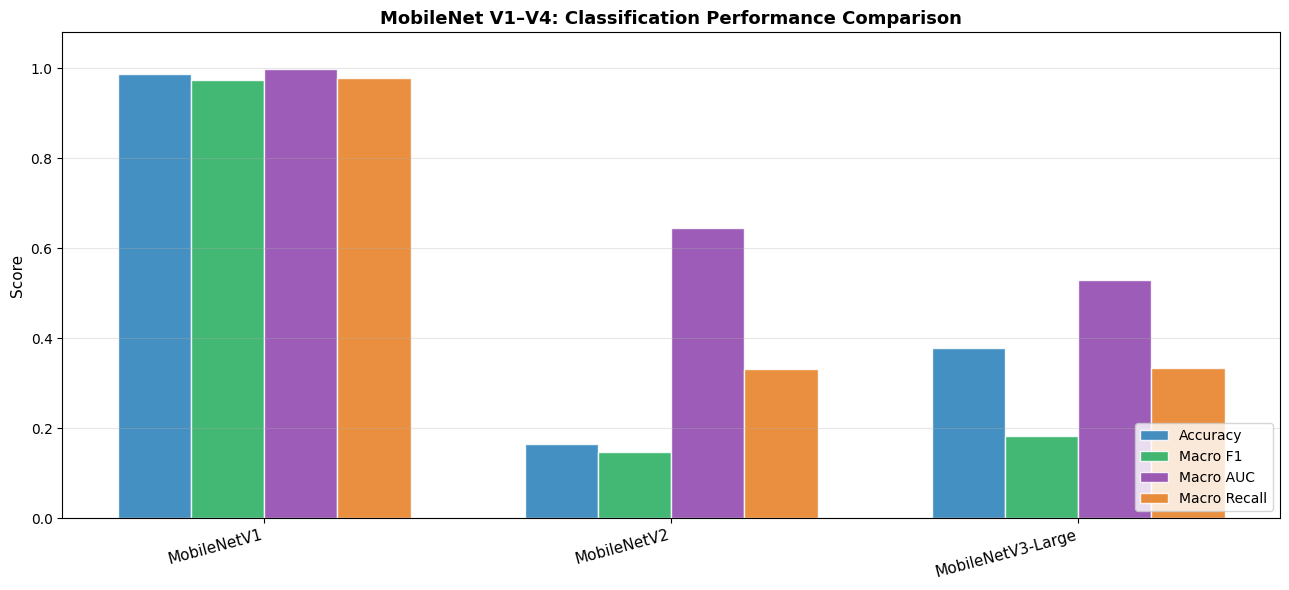

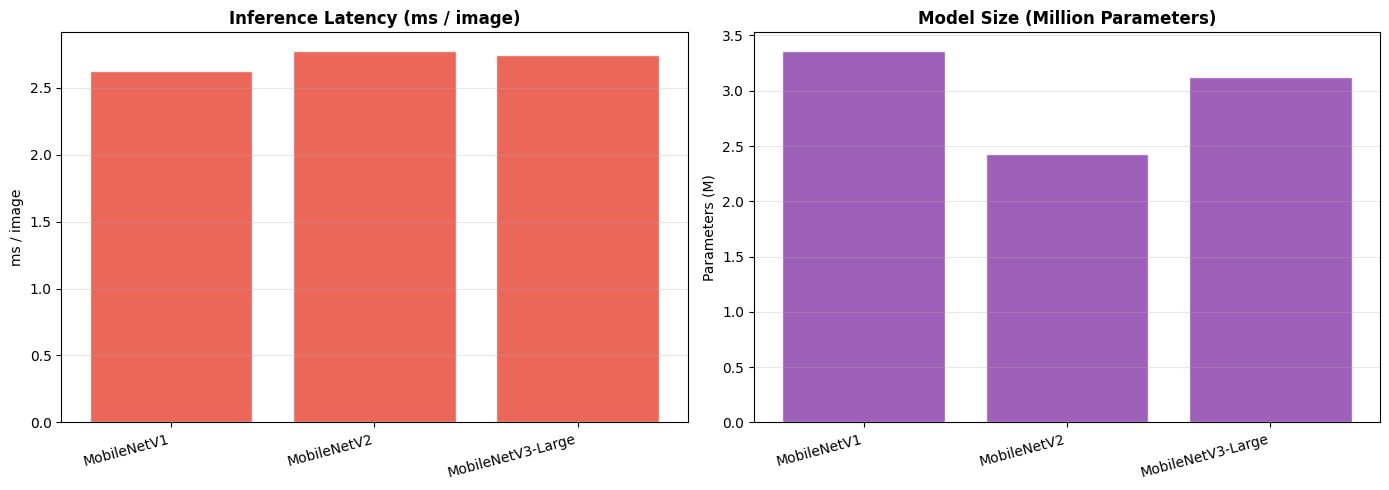

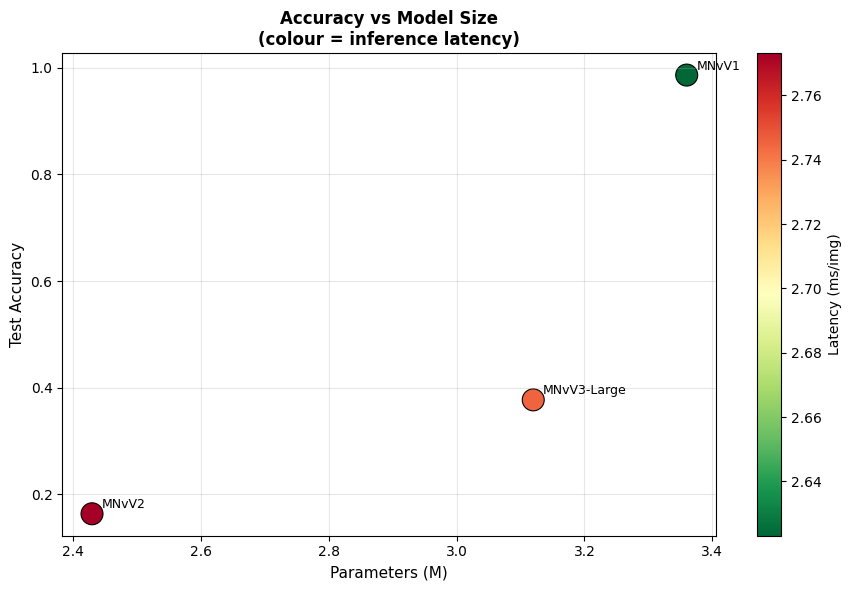

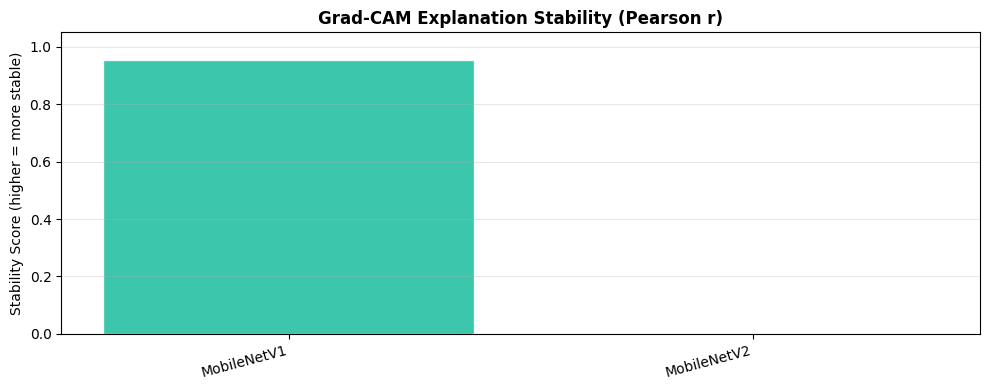

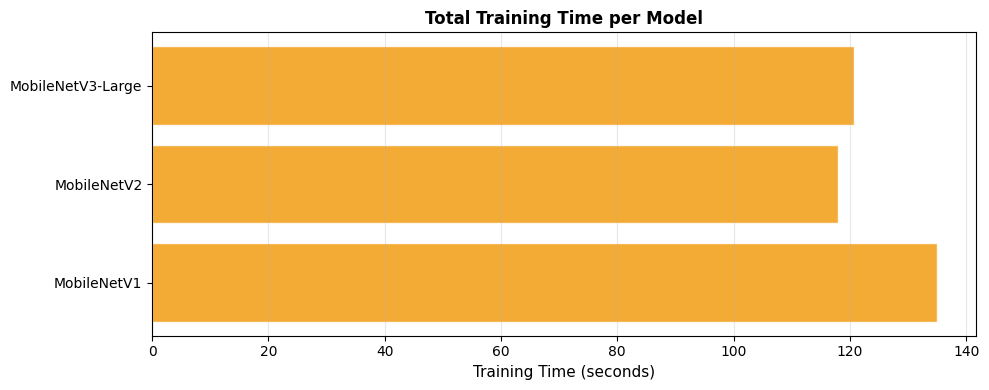

In [ ]:
# ==========================================
# CELL 15: COMPARISON CHARTS
# ==========================================

model_names = df['Model'].tolist()
x     = np.arange(len(model_names))
bar_w = 0.18
palette = ['#2980b9','#27ae60','#8e44ad','#e67e22']

# ---- Chart 1: Accuracy / F1 / AUC / Recall ----
fig, ax = plt.subplots(figsize=(13, 6))
metrics = [('accuracy','Accuracy'),('macro_f1','Macro F1'),
           ('macro_auc','Macro AUC'),('macro_rec','Macro Recall')]
for j, (col, label) in enumerate(metrics):
    ax.bar(x + j*bar_w, df[col], bar_w, label=label,
           color=palette[j], alpha=0.87, edgecolor='white')
ax.set_xticks(x + bar_w*1.5)
ax.set_xticklabels(model_names, rotation=15, ha='right', fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('MobileNet V1–V4: Classification Performance Comparison',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 2: Latency vs Parameters ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(model_names, df['latency_ms'], color='#e74c3c', alpha=0.85, edgecolor='white')
axes[0].set_title('Inference Latency (ms / image)', fontweight='bold')
axes[0].set_ylabel('ms / image')
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(model_names, df['params_M'], color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1].set_title('Model Size (Million Parameters)', fontweight='bold')
axes[1].set_ylabel('Parameters (M)')
axes[1].set_xticklabels(model_names, rotation=15, ha='right')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 3: Accuracy vs Model Size (efficiency frontier) ----
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(df['params_M'], df['accuracy'],
                c=df['latency_ms'], cmap='RdYlGn_r',
                s=250, edgecolors='black', linewidths=0.8)
for _, row in df.iterrows():
    ax.annotate(row['Model'].replace('MobileNet','MNv'),
                (row['params_M'], row['accuracy']),
                textcoords='offset points', xytext=(7, 4), fontsize=9)
plt.colorbar(sc, ax=ax, label='Latency (ms/img)')
ax.set_xlabel('Parameters (M)', fontsize=11)
ax.set_ylabel('Test Accuracy', fontsize=11)
ax.set_title('Accuracy vs Model Size\n(colour = inference latency)',
             fontweight='bold')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---- Chart 4: Stability scores ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(model_names, df['stability'], color='#1abc9c', alpha=0.85, edgecolor='white')
ax.set_ylim(0, 1.05)
ax.set_title('Grad-CAM Explanation Stability (Pearson r)', fontweight='bold')
ax.set_ylabel('Stability Score (higher = more stable)')
ax.set_xticklabels(model_names, rotation=15, ha='right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 5: Training time ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(model_names, df['train_time_s'], color='#f39c12', alpha=0.85, edgecolor='white')
ax.set_xlabel('Training Time (seconds)', fontsize=11)
ax.set_title('Total Training Time per Model', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# ==========================================
# CELL 16: FINAL RANKING & RECOMMENDATION
# ==========================================

df['norm_latency']  = (df['latency_ms'] - df['latency_ms'].min()) / \
                      (df['latency_ms'].max() - df['latency_ms'].min() + 1e-9)
df['norm_stability']= (df['stability']  - df['stability'].min())  / \
                      (df['stability'].max()  - df['stability'].min()  + 1e-9)

# Composite = 35% Acc + 25% F1 + 20% AUC + 10% Speed + 10% Stability
df['composite'] = (
    0.35 * df['accuracy']       +
    0.25 * df['macro_f1']       +
    0.20 * df['macro_auc']      +
    0.10 * (1 - df['norm_latency'])  +
    0.10 * df['norm_stability']
).round(4)

df_rank = df[['Model','accuracy','macro_f1','macro_auc',
              'latency_ms','params_M','stability','composite']]\
            .sort_values('composite', ascending=False).reset_index(drop=True)
df_rank.index += 1
df_rank.index.name = 'Rank'

print("\n" + "="*85)
print("  FINAL RANKING — MobileNet V1 / V2 / V3 / V4")
print("  IQ-OTH/NCCD Lung Cancer Detection")
print("="*85)
print(df_rank.round(4).to_string())
print("\nComposite = 35% Accuracy + 25% F1 + 20% AUC + 10% Speed + 10% Stability")

winner = df_rank.iloc[0]
print("\n" + "-"*85)
print(f"  RECOMMENDED MODEL : {winner['Model']}")
print(f"  Accuracy  : {winner['accuracy']:.4f}")
print(f"  Macro F1  : {winner['macro_f1']:.4f}")
print(f"  Macro AUC : {winner['macro_auc']:.4f}")
print(f"  Latency   : {winner['latency_ms']:.2f} ms/image")
print(f"  Stability : {winner['stability']:.4f}")
print("-"*85)


  FINAL RANKING — MobileNet V1 / V2 / V3 / V4
  IQ-OTH/NCCD Lung Cancer Detection
                  Model  accuracy  macro_f1  macro_auc  latency_ms  params_M  stability  composite
Rank                                                                                              
1           MobileNetV1    0.9864    0.9735     0.9994      2.6231      3.36     0.9524     0.9885
2           MobileNetV2    0.1636    0.1468     0.6453      2.7731      2.43    -0.3918     0.2230
3     MobileNetV3-Large    0.3773    0.1826     0.5297      2.7452      3.12        NaN        NaN

Composite = 35% Accuracy + 25% F1 + 20% AUC + 10% Speed + 10% Stability

-------------------------------------------------------------------------------------
  RECOMMENDED MODEL : MobileNetV1
  Accuracy  : 0.9864
  Macro F1  : 0.9735
  Macro AUC : 0.9994
  Latency   : 2.62 ms/image
  Stability : 0.9524
-------------------------------------------------------------------------------------


In [ ]:
# ==========================================
# CELL 17: SAVE RESULTS TO GOOGLE DRIVE
# ==========================================
save_path = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/mobilenet_v1_v4_results.csv'
df_rank.to_csv(save_path)
print(f"Results saved to: {save_path}")

Results saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/mobilenet_v1_v4_results.csv
